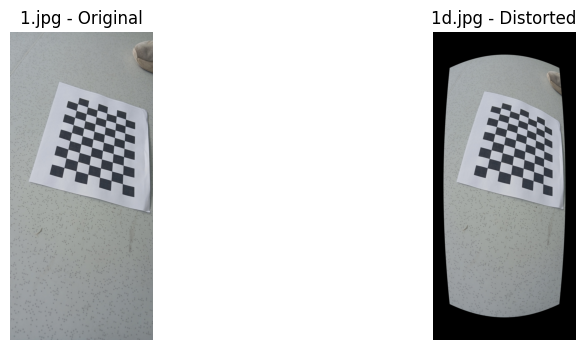

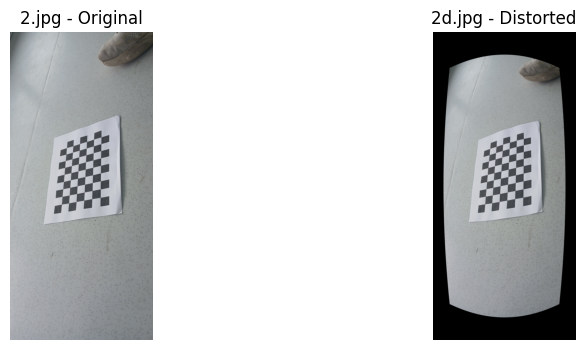

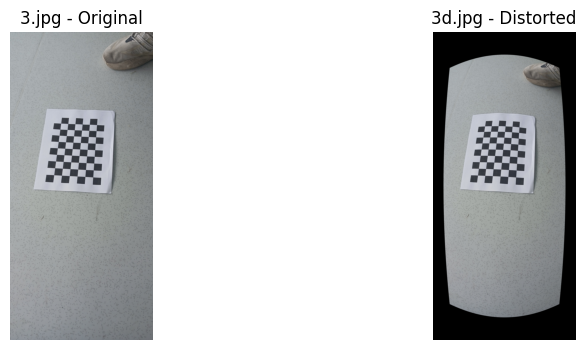

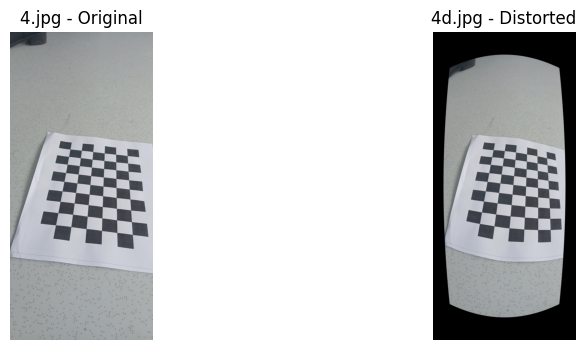

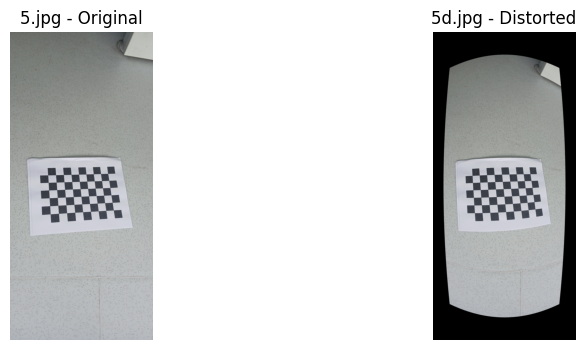

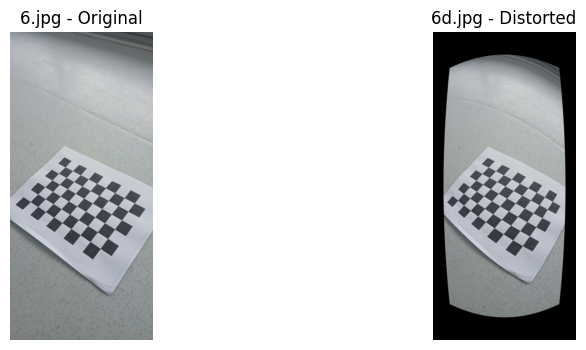

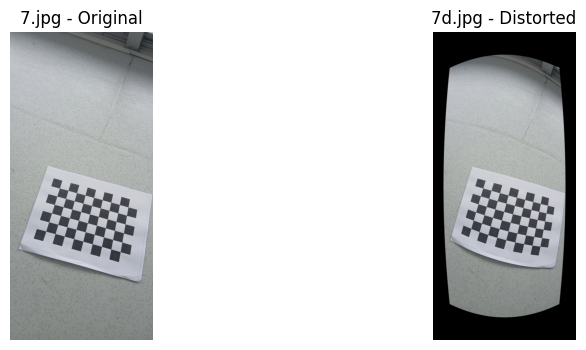

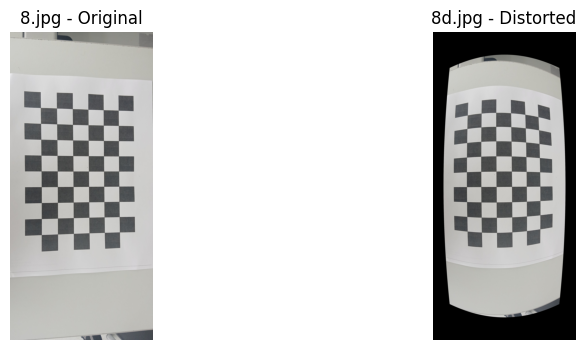

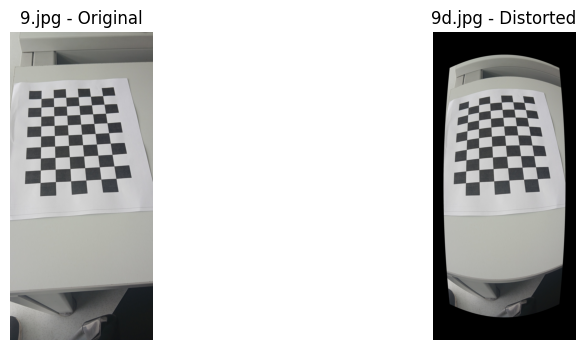

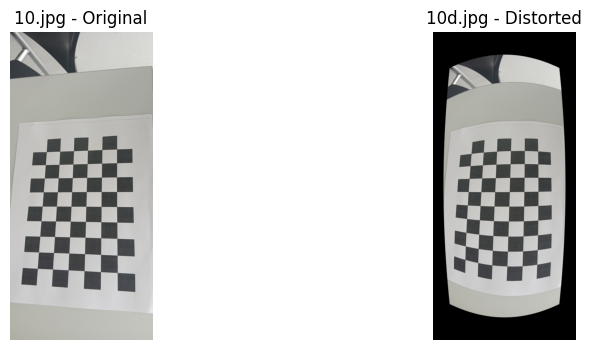

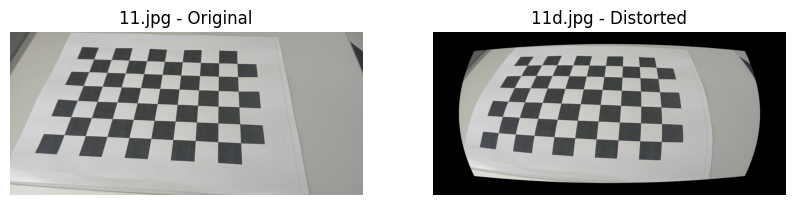

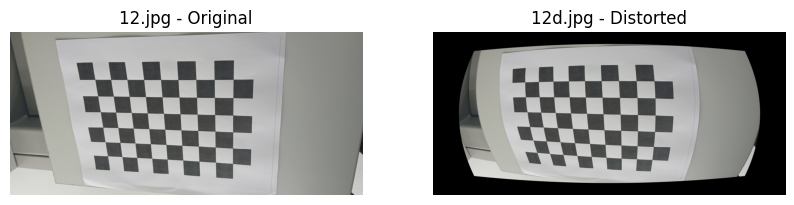

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def apply_radial_distortion(img, k1=0.0005, k2=0.00001):
    h, w = img.shape[:2]
    cx, cy = w / 2, h / 2

    # Create a normalized coordinate grid [-1, 1]
    x, y = np.meshgrid(np.linspace(0, w - 1, w), np.linspace(0, h - 1, h))
    x_norm = (x - cx) / cx
    y_norm = (y - cy) / cy
    r2 = x_norm**2 + y_norm**2

    # Apply radial distortion formula
    x_distorted = x_norm * (1 + k1 * r2 + k2 * r2**2)
    y_distorted = y_norm * (1 + k1 * r2 + k2 * r2**2)

    # Map back to pixel coordinates
    map_x = (x_distorted * cx + cx).astype(np.float32)
    map_y = (y_distorted * cy + cy).astype(np.float32)

    # Remap image using distorted coordinates
    distorted = cv2.remap(img, map_x, map_y, interpolation=cv2.INTER_LINEAR)
    return distorted

# Main loop to process and save
for i in range(1, 13):
    filename = f"{i}.jpg"
    img = cv2.imread(filename)
    if img is None:
        print(f"Image {filename} not found.")
        continue

    distorted_img = apply_radial_distortion(img, k1=0.2, k2=0.05)  # Adjust strength here

    # Save and show
    output_name = f"{i}d.jpg"
    cv2.imwrite(output_name, distorted_img)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{i}.jpg - Original")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(distorted_img, cv2.COLOR_BGR2RGB))
    plt.title(f"{i}d.jpg - Distorted")
    plt.axis('off')
    plt.show()
